# Лабораторная работа №1 - Регрессия

Цель - предсказывание *quality* по параметрам вина.

# Анализ данных.

Shape: (1599, 12)
Coloumns: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']
Quality column description:


count    1599.000000
mean        5.636023
std         0.807569
min         3.000000
25%         5.000000
50%         6.000000
75%         6.000000
max         8.000000
Name: quality, dtype: float64

Head of dataset:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


Duplicated rows cnt:


240

Null rows cnt:


fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

fixed acidity


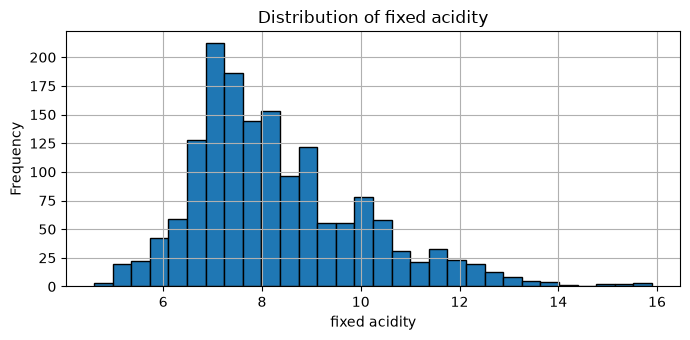

Outlier cnt of fixed acidity: 49
volatile acidity


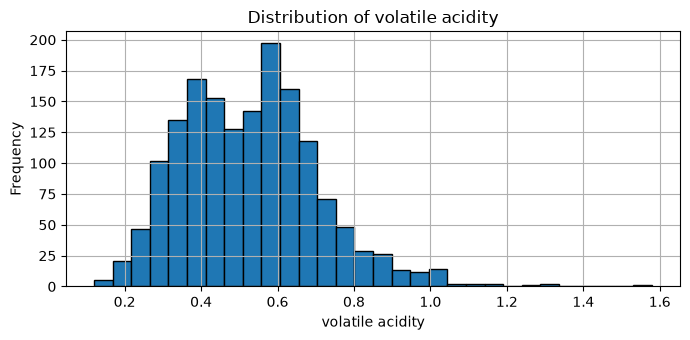

Outlier cnt of volatile acidity: 19
citric acid


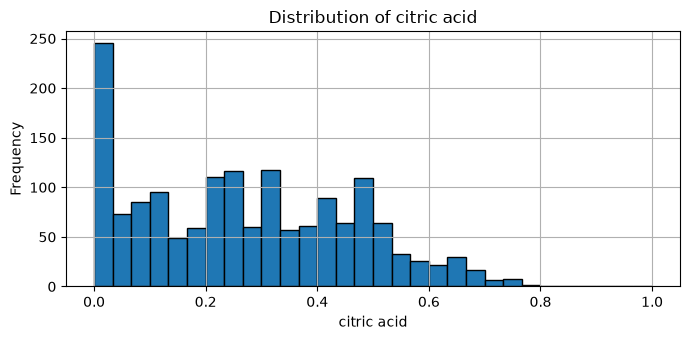

Outlier cnt of citric acid: 1
residual sugar


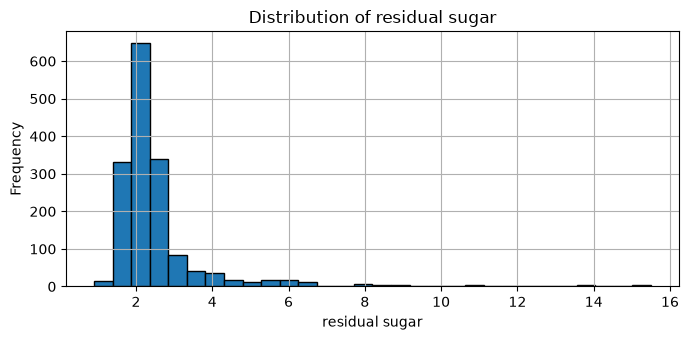

Outlier cnt of residual sugar: 155
chlorides


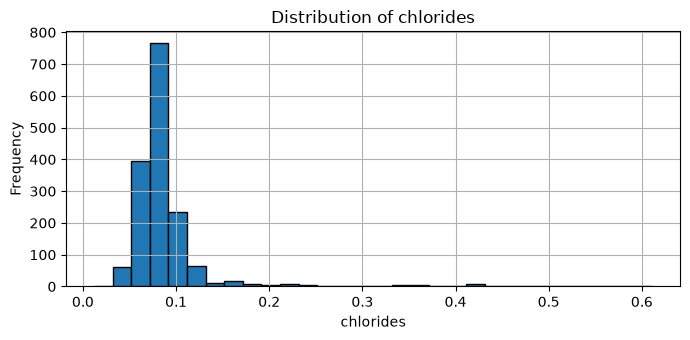

Outlier cnt of chlorides: 112
free sulfur dioxide


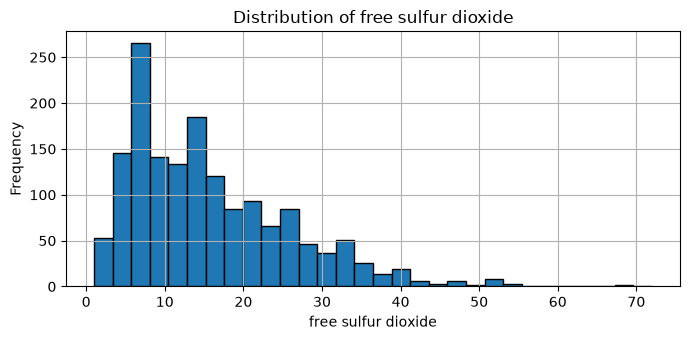

Outlier cnt of free sulfur dioxide: 30
total sulfur dioxide


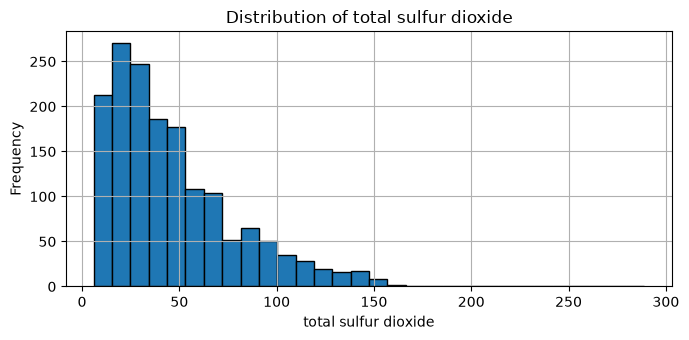

Outlier cnt of total sulfur dioxide: 55
density


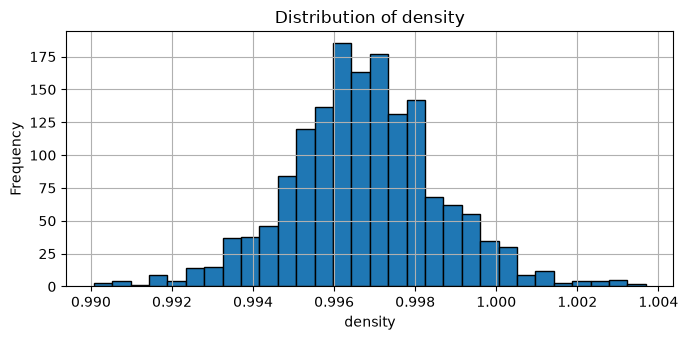

Outlier cnt of density: 45
pH


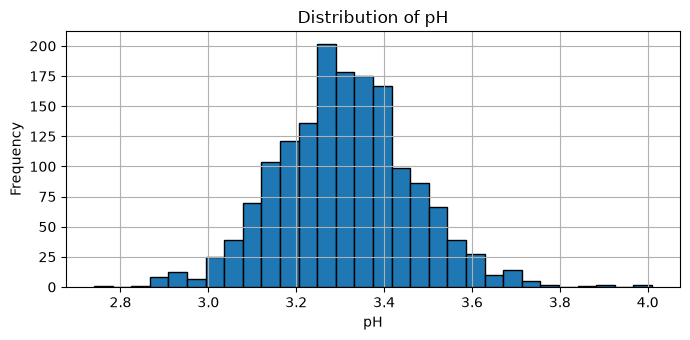

Outlier cnt of pH: 35
sulphates


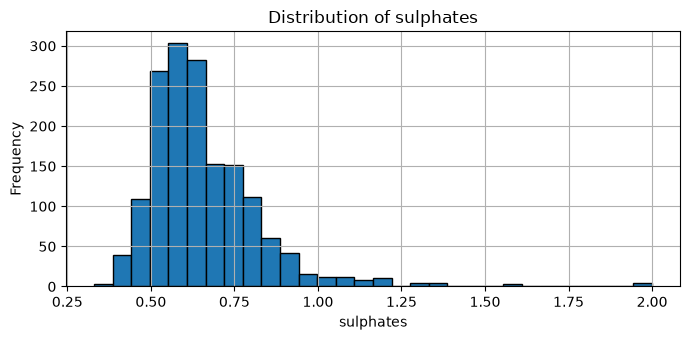

Outlier cnt of sulphates: 59
alcohol


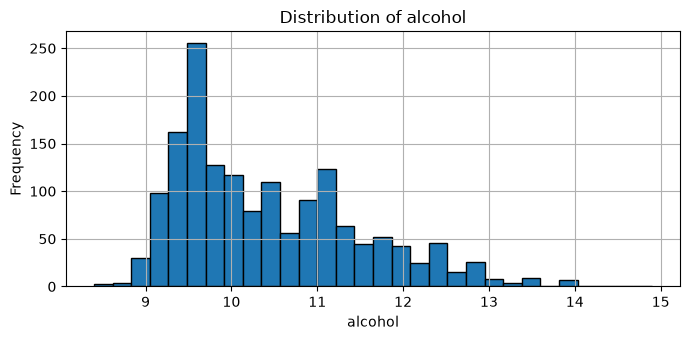

Outlier cnt of alcohol: 13
quality


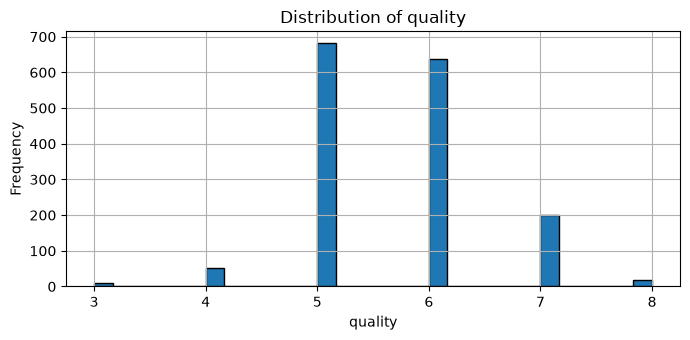

Outlier cnt of quality: 28


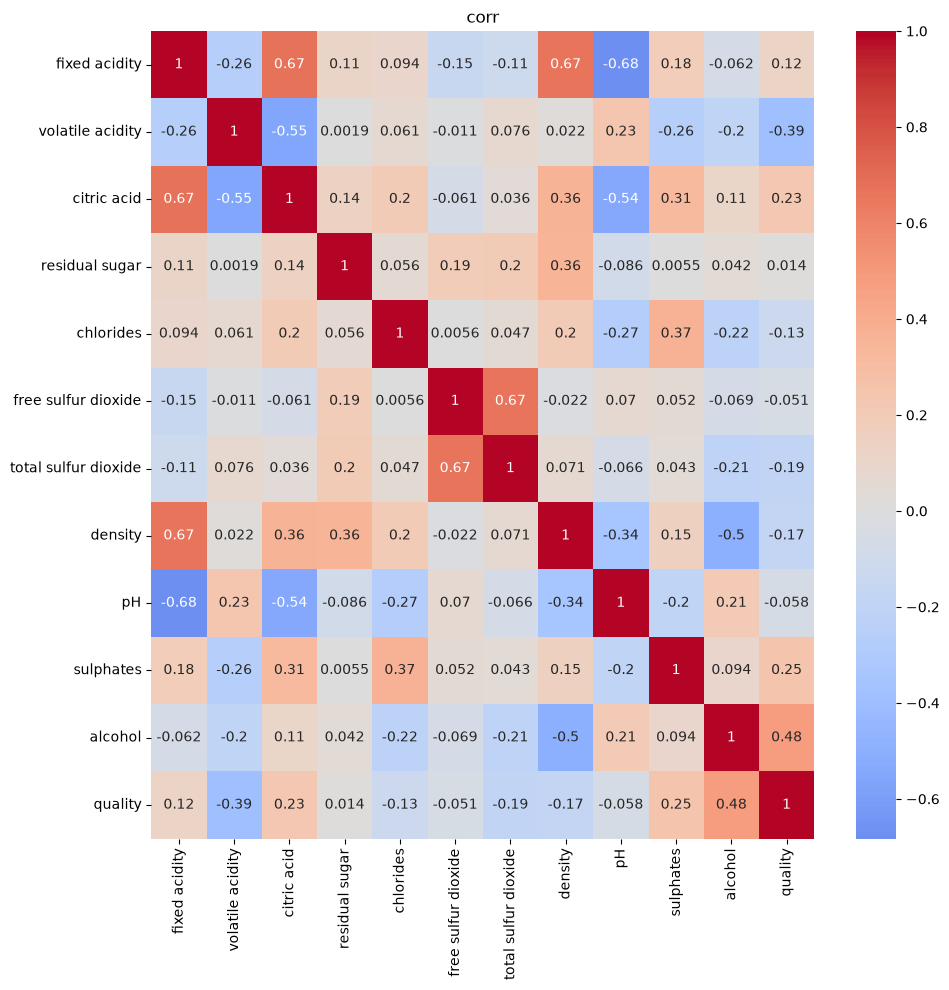

In [34]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


def describe_coloumn(df: pd.DataFrame, column: str):
    print(column)
    _, ax = plt.subplots(figsize=(7, 3.5))
    df[column].hist(ax=ax, bins=30, edgecolor='black')
    ax.set_title(f"Distribution of {column}")
    ax.set_xlabel(column)
    ax.set_ylabel("Frequency")
    plt.tight_layout()
    plt.show()
    df[column].describe()

    Q1, Q3 = df[column].quantile([0.25, 0.75])
    IQR = Q3 - Q1
    outliers = df[(df[column] < Q1 - IQR * 1.5) | (df[column] > Q3 + IQR * 1.5)]
    print(f"Outlier cnt of {column}: {len(outliers)}")


url_red = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
url_white = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv"

df_red = pd.read_csv(url_red, sep=';')
df_white = pd.read_csv(url_white, sep=';')

#df_red['red'] = 1
#df_white['red'] = 0

df = df_red

print(f"Shape: {df.shape}")
print(f"Coloumns: {df.columns.to_list()}")
print("Quality column description:")
display(df["quality"].describe())
print("Head of dataset:")
display(df.head())
print("Duplicated rows cnt:")
display(int(df.duplicated().sum()))
print("Null rows cnt:")
display(df.isnull().sum())

for col in df.columns:
    describe_coloumn(df, col)

fig, ax = plt.subplots(figsize=(10, 10))

corr = df.corr(numeric_only=True)

sns.heatmap(corr, ax=ax, center=0, annot=True, cmap='coolwarm') # type: ignore
plt.title('corr')
plt.tight_layout()
plt.show()


DataFrame состоит из 1599 строк с 12 столбцами. Они перечислены в выводе скрипта.

Дубликатов -- 240 строк. Это примерно $15$% от всего датасета. Для обучения стоит исключить дубликаты.

"В среднем" (обычно) качество вина - число от 5 до 6. Только доли получают остальные оценки.

Как видно из таблицы корреляций качества и остальных признаков: нет ни одной сильной корреляции ($|r| > 0.7$). 
Средняя корреляция выявлена у параметров: "volatile acidity", "alcohol" - отрицательная и положительная соответсвенно. То есть, чем больше нестабильной кислотности, тем оценка ниже и чем выше содержание этанола - тем выше. Остальные параметры имеют с качеством низкую корреляцию.

Как видно из корреляций почти нулевую имеют: "pH", "free sulfiric dioxide", "residual sugar". Значит, линейной зависимости между этими параметрами почти нет.

# Fix skew

In [35]:
from sklearn.base import BaseEstimator, TransformerMixin

class SkewFixer(BaseEstimator, TransformerMixin):
    def __init__(self, threshold: float=1.0):
        self.threshold = threshold 

    def fit(self, X: pd.DataFrame, y: pd.Series | None=None):
        skews = X.skew()
        self.coloumns_ = skews[skews.abs() > self.threshold].index.to_list()
        return self

    def transform(self, X: pd.DataFrame):
        new_x = X.copy()
        for col in self.coloumns_:
            new_x[col] = np.log1p(X[col])
        return new_x

    def get_feature_names_out(self, input_features=None):
        return np.array(input_features)



# Poly some features

In [36]:
from itertools import combinations_with_replacement

from sklearn.base import BaseEstimator, TransformerMixin

class PolySomeColmuns(BaseEstimator, TransformerMixin):
    def __init__(self, columns: list[str]):
        self.columns = columns

    def fit(self, X: pd.DataFrame, y:pd.Series | None=None):
        self.columns_: list[str] = []
        x_index = X.columns.to_list()
        for col in self.columns:
            if col in x_index:
                self.columns_.append(col)
        return self

    def transform(self, X: pd.DataFrame):
        new_x = X.copy()
        for fst, snd in combinations_with_replacement(self.columns_, 2):
            if fst != snd:
                new_x[f'{fst} * {snd}'] = new_x[fst] * new_x[snd] 
            else:
                new_x[f'{fst}^2'] = new_x[fst] ** 2
        return new_x

    def get_feature_names_out(self, input_features=None):
        base = list(input_features) if input_features is not None else []
        extras = [
            f'{fst}^2' if fst == snd else f'{fst} * {snd}'
            for fst, snd in combinations_with_replacement(self.columns_, 2)
        ]
        return np.array(base + extras)

Разделим выборку на train и test.

In [37]:
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
TEST_SIZE = 0.2

# df = df.drop_duplicates()

X = df.drop(columns=['quality'])
y = df['quality']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE
)

print(X_train.shape, X_test.shape)


(1279, 11) (320, 11)


Разбили недубликатные строки 80-20. Размеры показаны выше.

Такой способ был выбран, для того, чтобы оставить достаточное количество данных для train и имень достаточное количество данных на test. Если бы у нас было гораздо больше данных - можно было бы взять 90-10.

Если оценивать модель на одной и той же тестовой выборке - мы просто "подгонем" её под эту выборку, и, если тестовая выборка не покрывает нужного количества возможных данных, то на непроверенных данных у нас может сильно вырасти ошибка.

# Baseline

In [38]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

models = {}

def rmse(y_true, y_pred):
    return root_mean_squared_error(y_true, y_pred)

def mae(y_true, y_pred):
    return mean_absolute_error(y_true, y_pred)

baseline = Pipeline([
    ('log', SkewFixer()),
    ('poly', PolySomeColmuns([
        'alcohol', 
        'volatile acidity', 
        'sulphates', 
        ])),
    ("scaler", StandardScaler()),
    ("model", DummyRegressor(strategy='mean')),
])

baseline.fit(X_train, y_train)

pred_base = baseline.predict(X_test)
print("Baseline RMSE: ", rmse(y_test, pred_base))
print("Baseline MAE: ", mae(y_test, pred_base))
models["Baseline"] = baseline

Baseline RMSE:  0.81065409945582
Baseline MAE:  0.6852839132134478


# Linear

In [39]:
from sklearn.linear_model import LinearRegression

linreg = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

linreg_modified = Pipeline([
    ('log', SkewFixer()),
    ('poly', PolySomeColmuns([
        'alcohol', 
        'volatile acidity', 
        'sulphates', 
        ])),
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

linreg.fit(X_train, y_train)
linreg_modified.fit(X_train, y_train)

pred_train = linreg.predict(X_train)
pred_test = linreg.predict(X_test)

pred_train_modified = linreg_modified.predict(X_train)
pred_test_modified = linreg_modified.predict(X_test)

print("Linear")
print("Train RMSE: ", rmse(y_train, pred_train))
print("Test RMSE: ", rmse(y_test, pred_test))
print("Test MAE: ", mae(y_test, pred_test))

coefs = pd.Series(linreg.named_steps["model"].coef_, index=linreg[:-1].get_feature_names_out(X_train.columns)).sort_values()
display(coefs)

print("Linear modified")
print("Train RMSE: ", rmse(y_train, pred_train_modified))
print("Test RMSE: ", rmse(y_test, pred_test_modified))
print("Test MAE: ", mae(y_test, pred_test_modified))

coefs = pd.Series(linreg_modified.named_steps["model"].coef_, index=linreg_modified[:-1].get_feature_names_out(X_train.columns)).sort_values()
display(coefs)

models["Linear"] = linreg
models["LinearModified"] = linreg_modified


Linear
Train RMSE:  0.6512995910592837
Test RMSE:  0.624519930798013
Test MAE:  0.5035304415524374


volatile acidity       -0.179439
total sulfur dioxide   -0.120008
chlorides              -0.089084
pH                     -0.060610
citric acid            -0.027512
density                -0.019204
residual sugar          0.009421
fixed acidity           0.039789
free sulfur dioxide     0.058015
sulphates               0.146815
alcohol                 0.296628
dtype: float64

Linear modified
Train RMSE:  0.6378892952751033
Test RMSE:  0.6096914332225336
Test MAE:  0.4903101802768301


sulphates^2                    -0.643441
alcohol^2                      -0.437361
alcohol * volatile acidity     -0.191531
total sulfur dioxide           -0.116687
volatile acidity^2             -0.098409
pH                             -0.087949
chlorides                      -0.054728
density                        -0.054138
citric acid                    -0.034378
volatile acidity * sulphates   -0.027668
residual sugar                  0.010341
fixed acidity                   0.033607
free sulfur dioxide             0.072973
volatile acidity                0.162306
sulphates                       0.412924
alcohol * sulphates             0.478113
alcohol                         0.543410
dtype: float64

Проведём регуляризацию

In [40]:
from sklearn.linear_model import Ridge, Lasso

ridge = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=1.0))
])

lasso = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Lasso(alpha=0.01, max_iter=10000))
])
ridge_modified = Pipeline([
    ('log', SkewFixer()),
    ('poly', PolySomeColmuns([
        'alcohol', 
        'volatile acidity', 
        'sulphates', 
        ])),
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=1.0))
])

lasso_modified = Pipeline([
    ('log', SkewFixer()),
    ('poly', PolySomeColmuns([
        'alcohol', 
        'volatile acidity', 
        'sulphates', 
        ])),
    ("scaler", StandardScaler()),
    ("model", Lasso(alpha=0.01, max_iter=10000))
])

for name, model in {"Ridge": ridge, "Lasso": lasso, "RidgeModified": ridge_modified, "LassoModified": lasso_modified}.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    print(name, 'RMSE = ', rmse(y_test, pred))
    print(name, 'MAE = ', mae(y_test, pred))
    coefs = pd.Series(model.named_steps['model'].coef_, index=model[:-1].get_feature_names_out(X_train.columns)).sort_values()
    display(coefs)
    models[name] = model

Ridge RMSE =  0.6245302281832383
Ridge MAE =  0.5035596204290793


volatile acidity       -0.179247
total sulfur dioxide   -0.119853
chlorides              -0.089027
pH                     -0.060181
citric acid            -0.027221
density                -0.019810
residual sugar          0.009602
fixed acidity           0.040235
free sulfur dioxide     0.057838
sulphates               0.146787
alcohol                 0.296075
dtype: float64

Lasso RMSE =  0.6269090970078781
Lasso MAE =  0.5077443121373395


volatile acidity       -0.171481
total sulfur dioxide   -0.095415
chlorides              -0.077486
pH                     -0.048951
density                -0.000000
residual sugar          0.000000
citric acid            -0.000000
fixed acidity           0.009898
free sulfur dioxide     0.030957
sulphates               0.131292
alcohol                 0.297999
dtype: float64

RidgeModified RMSE =  0.6091207603744073
RidgeModified MAE =  0.4904261540110932


sulphates^2                    -0.615603
alcohol^2                      -0.271374
alcohol * volatile acidity     -0.138184
total sulfur dioxide           -0.119876
pH                             -0.087630
volatile acidity^2             -0.087237
chlorides                      -0.056409
density                        -0.052062
citric acid                    -0.034301
volatile acidity * sulphates   -0.014738
residual sugar                  0.009869
fixed acidity                   0.033501
free sulfur dioxide             0.075275
volatile acidity                0.083874
alcohol                         0.359471
sulphates                       0.372120
alcohol * sulphates             0.485493
dtype: float64

LassoModified RMSE =  0.6172875413660424
LassoModified MAE =  0.5000847201832215


sulphates^2                    -0.150572
total sulfur dioxide           -0.094184
volatile acidity^2             -0.082483
volatile acidity               -0.077410
chlorides                      -0.068756
pH                             -0.055672
density                        -0.002235
citric acid                    -0.000000
volatile acidity * sulphates   -0.000000
alcohol * volatile acidity     -0.000000
alcohol^2                       0.000000
sulphates                       0.000000
residual sugar                 -0.000000
fixed acidity                   0.002452
free sulfur dioxide             0.043059
alcohol                         0.126550
alcohol * sulphates             0.363000
dtype: float64

Для того, чтобы понизить RMSE было предпринято много разных попыток: добавление новых фич, зависящих от старых (там, увы, получалась большая корреляция), логарифмизация "скошенных" данных, добавление квардратичных и кубичиских многочленов. По отдельности, влияние было довольно слабым или даже отрицательным, но объеденив логарифмизацию и возведение в степень, получился прирост примерно в 0.01-0.02 на данном train/test split'е. На модифицированном датасете наблюдается, что именно произведения влияют больше всего, возможно, это связано как-то с их химией.

Среди чисто линейных самые важные признаки: содержание алкоголя, содержание летучих кислот, содержание сульфаты. Среди модифицированных - произведение алкоголя на сульфаты, квадрат сульфатов, алкоголь.

# Нелинейные модели

## Случайный лес

In [41]:
from sklearn.ensemble import RandomForestRegressor

random_forest = Pipeline([
    ('model', RandomForestRegressor(
        n_estimators=500,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

random_forest.fit(X_train, y_train)

train_prediction = random_forest.predict(X_train)
test_prediction = random_forest.predict(X_test)
print("Random Forest Regressor")
print("Train RMSE = ", rmse(y_train, train_prediction))
print("Train MAE = ", mae(y_train, train_prediction))
print("Test RMSE = ", rmse(y_test, test_prediction))
print("Test MAE = ", mae(y_test, test_prediction))

models["Forest"] = random_forest

Random Forest Regressor
Train RMSE =  0.21570439912753533
Train MAE =  0.15179671618451912
Test RMSE =  0.5546299892721273
Test MAE =  0.4255


По сравнению с линейными на test падение составляет примерно 0.01-0.02 на данном split. Посмотрим на feature importance.

In [42]:
imp = pd.Series(
    random_forest.named_steps['model'].feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

display(imp.round(4))


alcohol                 0.2715
sulphates               0.1533
volatile acidity        0.1073
total sulfur dioxide    0.0777
chlorides               0.0682
pH                      0.0605
residual sugar          0.0586
density                 0.0536
fixed acidity           0.0532
citric acid             0.0485
free sulfur dioxide     0.0477
dtype: float64

Так как в лесе нет дополнительных фичей, будем сравнивать с обычной линейной. В топ 3 по влиянию все те же фичи, но сульфаты и летучие кислоты поменялись местами.

## Градиентный бустинг

In [43]:
from sklearn.ensemble import GradientBoostingRegressor

gradient_boosting = Pipeline([
    ('model', GradientBoostingRegressor(
        random_state = RANDOM_STATE
        )
    )
])

gradient_boosting.fit(X_train, y_train)

train_prediction= gradient_boosting.predict(X_train)
test_prediction= gradient_boosting.predict(X_test)

print("Gradient boosting")
print("Train RMSE = ", rmse(y_train, train_prediction))
print("Train MAE = ", mae(y_train, train_prediction))
print("Test RMSE = ", rmse(y_test, test_prediction))
print("Test MAE = ", mae(y_test, test_prediction))

models['Gradient Boosting'] = gradient_boosting

Gradient boosting
Train RMSE =  0.49896890603727206
Train MAE =  0.3873293051378686
Test RMSE =  0.6019428810232667
Test MAE =  0.48493624442420186


In [44]:
imp = pd.Series(
    gradient_boosting.named_steps['model'].feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

display(imp.round(4))

alcohol                 0.3760
sulphates               0.1943
volatile acidity        0.1254
total sulfur dioxide    0.0752
fixed acidity           0.0569
chlorides               0.0395
pH                      0.0337
residual sugar          0.0304
density                 0.0288
citric acid             0.0201
free sulfur dioxide     0.0198
dtype: float64

Топ 3 признака совпадают со случайным лесом.

# Тесты всех моделей

In [45]:
from typing import Any

def test_model(model: Pipeline):
    prediction = model.predict(X_test)

    return rmse(y_test, prediction), mae(y_test, prediction) 

rows: list[dict[str, Any]] = []
for name, model in models.items(): # type: ignore
    rmse_value, mae_value = test_model(model) # type: ignore
    rows.append({ # type: ignore
        'model': name,
        'rmse': rmse_value,
        'mae': mae_value,
    })

result = pd.DataFrame(rows).set_index('model')
result = result.sort_values('rmse', ascending=True)
display(result)



,rmse,mae
model,,
Forest,0.554630,0.425500
Gradient Boosting,0.601943,0.484936
RidgeModified,0.609121,0.490426
LinearModified,0.609691,0.490310
LassoModified,0.617288,0.500085
Linear,0.624520,0.503530
Ridge,0.624530,0.503560
Lasso,0.626909,0.507744
Baseline,0.810654,0.685284


В результате все модели оказались лучше Baseline и уложились в RMSE < 0.7 на данном split. Самым лучшим алгоритмом оказался random forest regressor. Это объясняется тем, что у GB более сложная регуляризация (больше гиперпараметров) и у нас малое количество данных. Так же, обратим внимание на линейные модели - хоть они и проиграли, но всё равно показывают интересную "динамику" в своей группе. Благодаря feature enginring и логарифмизации некоторых параметров получилось сбить примерно 0.015 RMSE по сравнению с обычными.

# Feature importance

Как было сказано ранее, в топ 3 вошли: содержание алкоголя, летучие кислоты и сульфаты. Единственное отличие между линейными и лесом - это места летучих кислот и сульфатов. При анализе был выделен алкоголь и летучие кислоты, но не были выделены сульфаты, так как их линейная связь меньше остальных ($r < 0.3$, что показывает линейную зависимость). Как раз по 4-ому графику видно, что зависимость больше квадратичная, чем линейная.

Feature importance только показывает корреляцию между фичами и оценкой. Допустим, явно не будет верно сказать, что если в вине по линейной модели будет, 50% алкоголя, то оно будет 12 из 10.  

forest


alcohol                 0.271537
sulphates               0.153282
volatile acidity        0.107305
total sulfur dioxide    0.077703
chlorides               0.068155
pH                      0.060487
residual sugar          0.058573
density                 0.053627
fixed acidity           0.053151
citric acid             0.048496
free sulfur dioxide     0.047684
dtype: float64

gb


alcohol                 0.375965
sulphates               0.194299
volatile acidity        0.125359
total sulfur dioxide    0.075183
fixed acidity           0.056945
chlorides               0.039518
pH                      0.033658
residual sugar          0.030401
density                 0.028772
citric acid             0.020073
free sulfur dioxide     0.019828
dtype: float64

ridge


alcohol                 0.296075
volatile acidity        0.179247
sulphates               0.146787
total sulfur dioxide    0.119853
chlorides               0.089027
pH                      0.060181
free sulfur dioxide     0.057838
fixed acidity           0.040235
citric acid             0.027221
density                 0.019810
residual sugar          0.009602
dtype: float64

ridge mod


sulphates^2                     0.615603
alcohol * sulphates             0.485493
sulphates                       0.372120
alcohol                         0.359471
alcohol^2                       0.271374
alcohol * volatile acidity      0.138184
total sulfur dioxide            0.119876
pH                              0.087630
volatile acidity^2              0.087237
volatile acidity                0.083874
free sulfur dioxide             0.075275
chlorides                       0.056409
density                         0.052062
citric acid                     0.034301
fixed acidity                   0.033501
volatile acidity * sulphates    0.014738
residual sugar                  0.009869
dtype: float64

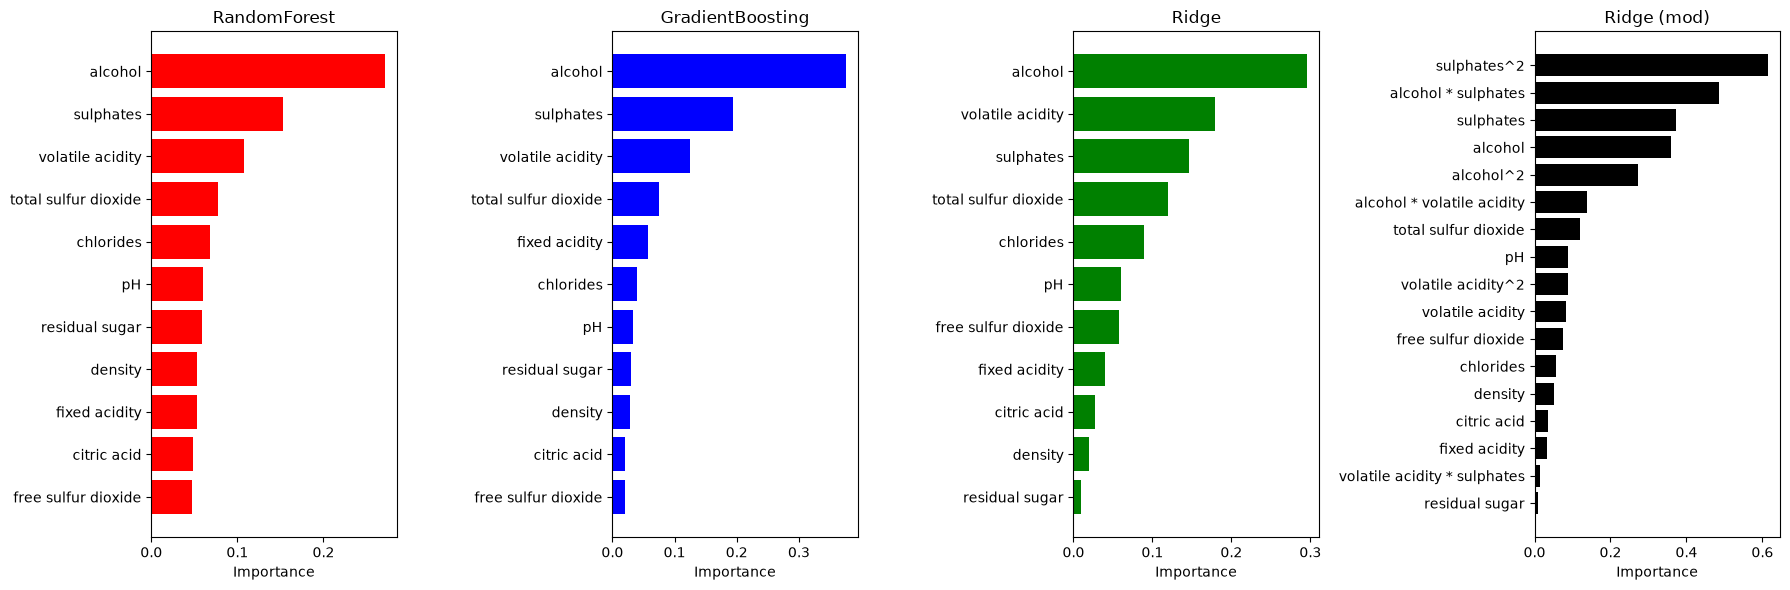

In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

imp_rf = pd.Series(
    models['Forest'].named_steps['model'].feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

imp_gb = pd.Series(
    models['Gradient Boosting'].named_steps['model'].feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

imp_linear = pd.Series(
    np.abs(models['Ridge'].named_steps['model'].coef_),
    index=X_train.columns
).sort_values(ascending=False)


imp_linear_mod = pd.Series(
    np.abs(models['RidgeModified'].named_steps['model'].coef_),
    index=models['RidgeModified'][:-1].get_feature_names_out(X_train.columns)
).sort_values(ascending=False)

print('forest')
display(imp_rf)
print('gb')
display(imp_gb)
print('ridge')
display(imp_linear)
print('ridge mod')
display(imp_linear_mod)

fig, axes = plt.subplots(1, 4, figsize=(18, 6))

for ax, imp, title, color in [
    (axes[0], imp_rf,     'RandomForest', 'red'),
    (axes[1], imp_gb,     'GradientBoosting',             'blue'),
    (axes[2], imp_linear, 'Ridge',             'green'),
    (axes[3], imp_linear_mod, 'Ridge (mod)',             'black'),
]:
    imp_sorted = imp.sort_values()
    ax.barh(imp_sorted.index, imp_sorted.values, color=color)
    ax.set_title(title)
    ax.set_xlabel('Importance')

plt.tight_layout()
plt.show()

# Анализ ошибок

Test RMSE: 0.5546
Test MAE:  0.4255
Max |error|: 2.3300
Median |error|: 0.3460


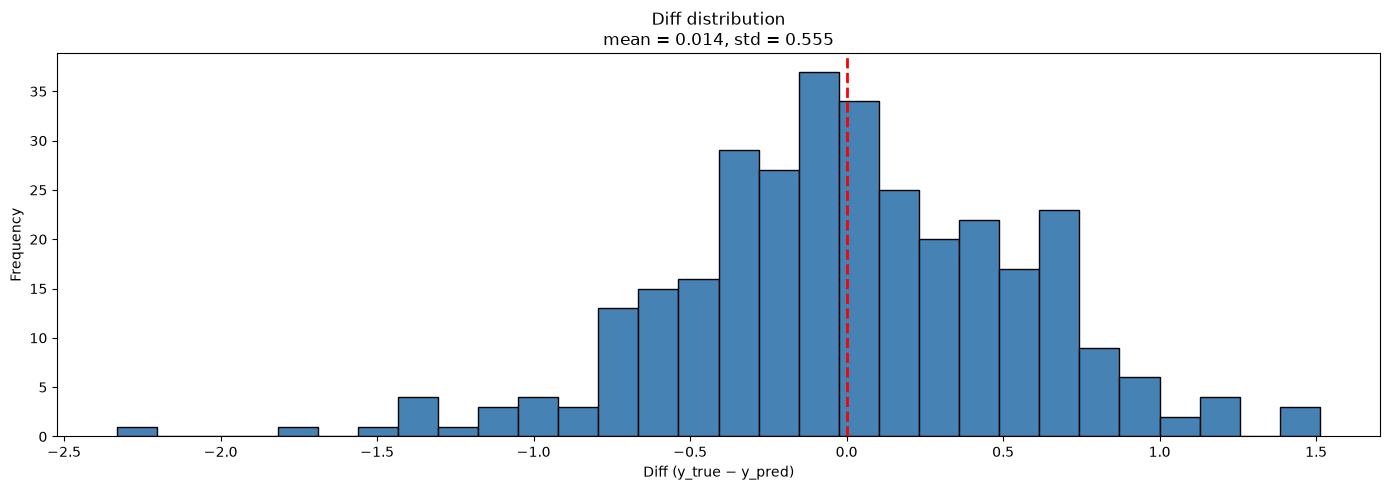

Mean diff:   +0.0137
Std diff:    0.5553


,y_true,y_pred,diff,abs_error
1505,3,5.330,-2.330,2.330
1484,4,5.806,-1.806,1.806
588,8,6.488,1.512,1.512
353,5,6.494,-1.494,1.494
1449,8,6.530,1.470,1.470


,y_true,y_pred,diff,abs_error
15,5,4.998,0.002,0.002
650,5,4.994,0.006,0.006
163,5,4.994,0.006,0.006
859,6,5.992,0.008,0.008
271,6,5.990,0.010,0.010


In [47]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

best_model = models['Forest']
pred_test = best_model.predict(X_test)
diff = y_test - pred_test

error_df = pd.DataFrame({
    'y_true':    y_test.values,
    'y_pred':    pred_test,
    'diff':  diff.values,
    'abs_error': np.abs(diff.values),
}, index=y_test.index)

print(f"Test RMSE: {rmse(y_test, pred_test):.4f}")
print(f"Test MAE:  {mae(y_test, pred_test):.4f}")
print(f"Max |error|: {error_df['abs_error'].max():.4f}")
print(f"Median |error|: {error_df['abs_error'].median():.4f}")

fig, axe = plt.subplots(figsize=(14, 5))

axe.hist(diff, bins=30, edgecolor='black', color='steelblue')
axe.axvline(0, color='red', linestyle='--', linewidth=2)
axe.set_xlabel('Diff (y_true − y_pred)')
axe.set_ylabel('Frequency')
axe.set_title(f'Diff distribution\nmean = {diff.mean():.3f}, std = {diff.std():.3f}')

plt.tight_layout()
plt.show()

print(f"Mean diff:   {diff.mean():+.4f}")
print(f"Std diff:    {diff.std():.4f}")

top_errors = error_df.sort_values('abs_error', ascending=False).head(5)
bottom_errors = error_df.sort_values('abs_error', ascending=True).head(5)
display(top_errors)
display(bottom_errors)

Как видно из топ 5 с самыми большими ошибками - это те, у которых оценка редкая в дата сете (кроме одной 5-ки, вероятно она тут из-за шума в данных). В данных не было достаточного количества вин с ныне редкой оценкой, поэтому модель ошиблась в результирующей оценке. А если посмотрим на противоположное - тут как раз в районе 5-6, так как большинство оценок - это 5 или 6.